### Framing the problem

Questions:
a- What exactly is predicted?

b- Supervised or unsupervised? Regression or classification?

c- Which metric would you use and why?

d- what would a dumb baseline be?


Answers:
a- The count of bikes rented per hour

b- It's supervised and Regression

c- We should use RMSE because RMSE punishes big misses more and if there are no bikes at a station during rush hour it should affect the metric a lot

d- A dumb baseline would be predicting the average cnt for every hour of the day

### Loading the data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.figsize": (10, 5), "axes.titlesize": 14, "axes.titleweight": "bold"})

df = pd.read_csv("../../data/hour.csv", parse_dates=["dteday"])

In [2]:
df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   instant     17379 non-null  int64         
 1   dteday      17379 non-null  datetime64[us]
 2   season      17379 non-null  int64         
 3   yr          17379 non-null  int64         
 4   mnth        17379 non-null  int64         
 5   hr          17379 non-null  int64         
 6   holiday     17379 non-null  int64         
 7   weekday     17379 non-null  int64         
 8   workingday  17379 non-null  int64         
 9   weathersit  17379 non-null  int64         
 10  temp        17379 non-null  float64       
 11  atemp       17379 non-null  float64       
 12  hum         17379 non-null  float64       
 13  windspeed   17379 non-null  float64       
 14  casual      17379 non-null  int64         
 15  registered  17379 non-null  int64         
 16  cnt         17379 non-null  int64

### Splitting the dataset

A random split wouldn't be a good idea in this case, because the amount of rentals doesn't vary much from hour to hour(making the generalization error rather optimistic). So it would make it very easy for the model to predict an hour's rental amounts if the hours around it are in the training set. Another reason is because of data drift, we want to test on the most up to date information since it's going to be used to make predictions in the near future.

In [4]:
TEST_START = pd.Timestamp("2012-10-01")
df_train = df[df["dteday"] < TEST_START]
df_test = df[df["dteday"] >= TEST_START]
assert ((len(df_train) + len(df_test)) == len(df)) 

### Visualization

In [5]:
df_train.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


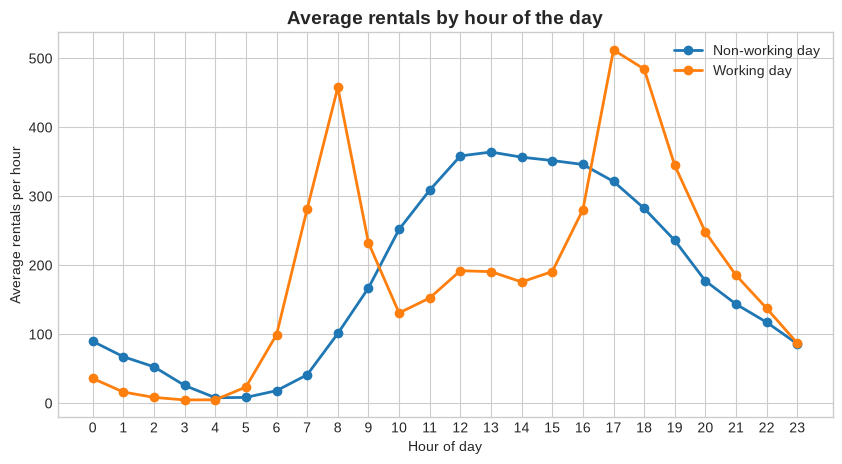

In [6]:
by_hour = (
    df_train.groupby(["hr", "workingday"])["cnt"].mean()
    .unstack()
    .rename(columns={0: "Non-working day", 1: "Working day"})
)

ax = by_hour.plot(marker="o", linewidth=2)
ax.set(title="Average rentals by hour of the day", xlabel="Hour of day", 
       ylabel="Average rentals per hour", xticks=range(24))
ax.legend(title=None)
plt.show()

This plot shows that when it's not a working day it the amount of rentals per hour has a single midday peek and when it's a working day it peeks at 8am and 5-6pm which seems to match usual work hours 

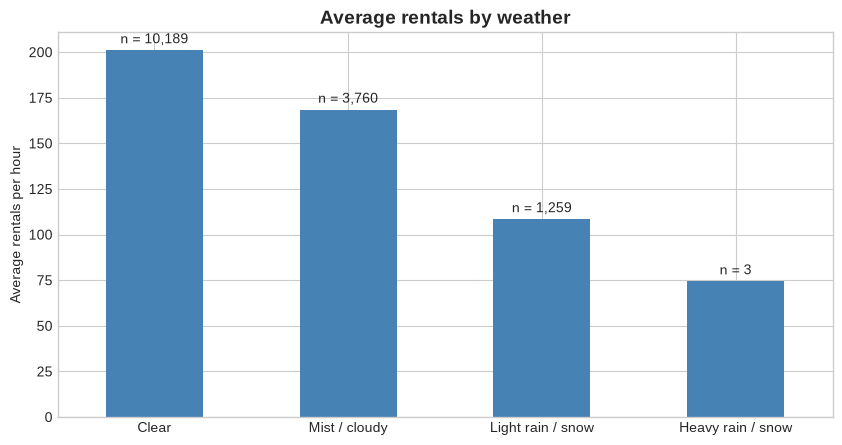

In [7]:
WEATHER_LABELS = {1: "Clear", 2: "Mist / cloudy", 3: "Light rain / snow", 4: "Heavy rain / snow"}

weather = df_train.groupby("weathersit")["cnt"].agg(["mean", "count"]).rename(index=WEATHER_LABELS)

ax = weather["mean"].plot(kind="bar", rot=0, color="steelblue")
ax.set(title="Average rentals by weather", xlabel=None, ylabel="Average rentals per hour")
ax.bar_label(ax.containers[0], labels=[f"n = {n:,}" for n in weather["count"]], padding=3)
plt.show()

This plot shows that the most amount of rentals is done when the weather is sunny or partly clouded and the least amount when the weather conditions are extreme(heavy storm, snow, fog, etc). So the weather seems to be important to determine the count of rentals.

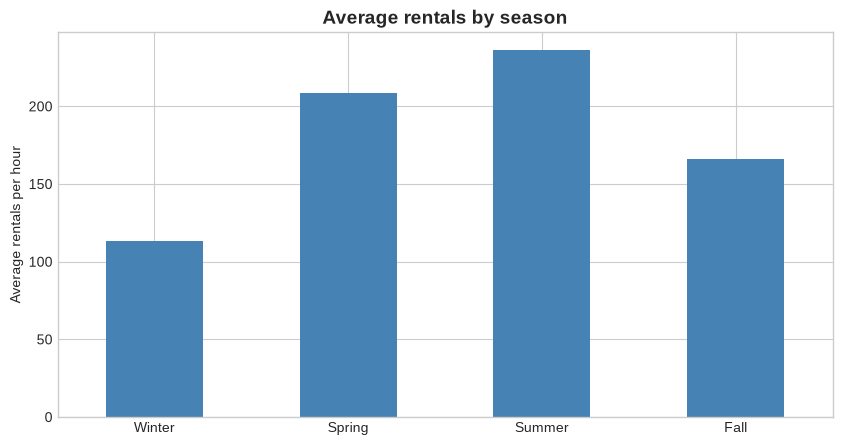

In [8]:
SEASON_LABELS = {1: "Winter", 2: "Spring", 3: "Summer", 4:"Fall"}
by_season = df_train.groupby("season")["cnt"].mean().rename(index=SEASON_LABELS)

ax = by_season.plot(kind="bar", rot=0, color="steelblue")
ax.set(title="Average rentals by season", xlabel=None, ylabel="Average rentals per hour")
plt.show()

In [9]:
pd.crosstab(df["mnth"], df["season"])

season,1,2,3,4
mnth,,,,
1,1429,0,0,0
2,1341,0,0,0
3,949,524,0,0
4,0,1437,0,0
5,0,1488,0,0
6,0,960,480,0
7,0,0,1488,0
8,0,0,1475,0
9,0,0,1053,384


In [10]:
df_train.groupby(["season", "yr"])["cnt"].agg(["mean", "count"]).unstack()

mean             count      
yr               0           1     0     1
season                                    
1        72.533849  157.290795  2068  1912
2       157.655924  258.963282  2203  2206
3       187.343750  284.343528  2240  2256
4       152.828960  317.010417  2134   192

Let's note a couple of things:

- The seasons don't really match the documentation ones, the real ones being 1: winter, 2: spring, 3:summer, 4:fall as the crosstab shows given that the data is from washington, those are the corresponding seasons for the geographical location. So the plot shows that the quietest season is winter and the most active one is summer.

- We can see from the grouping by year and season that the amount of rentals in 2011 was a lot lower so it grew in 2012. Aside from that we removed the last 3 months from the train set and put it in test, hence fall numbers are understated in the plot. This is called confounding where a third variable(year) is tied to both what we are looking at and the outcome, so it distorts the comparison. We could've done this within the same year for a fairer comparison. For example in 2011 the rentals per season from bigger to smaller are Summer, Spring, Fall and last Winter.

### Identifying the Leak

There is a leak with the columns casual and registered since the sum of this is equal to the cnt and you wouldn't have this to make the predictions until the hour is over

In [11]:
(df_train["casual"] + df_train["registered"] == df_train["cnt"]).all()

np.True_

### Columns that need to be dropped before modeling

- casual and registered need to be dropped because of the leak we showed, the reason being that we wouldn't have those columns when using it to predict

- We can drop the instant column since it just seems to be an id/counter

- We can drop the column dteday since we already have that information, and maybe extract day from it and have it as a column